# LeetCode #54: Spiral Matrix

https://leetcode.com/problems/spiral-matrix/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(m \cdot n)$ | $O(m \cdot n)$ |
| **Optimal: Boundary Shrinking ★** | $O(m \cdot n)$ | $O(1)$ extra |

---

## Understanding the Methods

### Brute Force
Mark visited cells with a separate boolean matrix and simulate the spiral direction changes. Correct but allocates an $O(m \cdot n)$ visited matrix.

### Optimal: Boundary Shrinking ★
Maintain four boundary pointers (`top`, `bottom`, `left`, `right`). Each spiral layer peels one row or column and shrinks the corresponding boundary inward. No visited matrix needed — the boundaries themselves encode which cells remain. Four traversals per layer, $O(m \cdot n)$ total touches, $O(1)$ extra space.

**Constraints:**
* $m = \text{matrix.length}$, $n = \text{matrix}[0]\text{.length}$
* $1 \leq m, n \leq 10$
* $-100 \leq \text{matrix}[i][j] \leq 100$


## Solutions

### C#

In [ ]:
public class Solution {
    public IList<int> SpiralOrder(int[][] matrix) {
        var result = new List<int>();
        int top = 0, bottom = matrix.Length - 1;
        int left = 0, right = matrix[0].Length - 1;

        while (top <= bottom && left <= right) {
            // Traverse right across the top boundary row
            for (int col = left; col <= right; col++) result.Add(matrix[top][col]);
            top++;
            // Traverse down along the right boundary column
            for (int row = top; row <= bottom; row++) result.Add(matrix[row][right]);
            right--;
            // Traverse left across the bottom boundary row (guard against single row)
            if (top <= bottom) {
                for (int col = right; col >= left; col--) result.Add(matrix[bottom][col]);
                bottom--;
            }
            // Traverse up along the left boundary column (guard against single column)
            if (left <= right) {
                for (int row = bottom; row >= top; row--) result.Add(matrix[row][left]);
                left++;
            }
        }
        return result;
    }
}

### Python

In [ ]:
class Solution:
    def spiral_order(self, matrix: list[list[int]]) -> list[int]:
        result = []
        top, bottom = 0, len(matrix) - 1
        left, right = 0, len(matrix[0]) - 1

        while top <= bottom and left <= right:
            # Traverse right across the top boundary row
            for col in range(left, right + 1):
                result.append(matrix[top][col])
            top += 1
            # Traverse down along the right boundary column
            for row in range(top, bottom + 1):
                result.append(matrix[row][right])
            right -= 1
            # Traverse left across the bottom boundary row (guard against single row)
            if top <= bottom:
                for col in range(right, left - 1, -1):
                    result.append(matrix[bottom][col])
                bottom -= 1
            # Traverse up along the left boundary column (guard against single column)
            if left <= right:
                for row in range(bottom, top - 1, -1):
                    result.append(matrix[row][left])
                left += 1
        return result

### Go

In [ ]:
func spiralOrder(matrix [][]int) []int {
    result := []int{}
    top, bottom := 0, len(matrix)-1
    left, right := 0, len(matrix[0])-1

    for top <= bottom && left <= right {
        // Traverse right across the top boundary row
        for col := left; col <= right; col++ {
            result = append(result, matrix[top][col])
        }
        top++
        // Traverse down along the right boundary column
        for row := top; row <= bottom; row++ {
            result = append(result, matrix[row][right])
        }
        right--
        // Traverse left across the bottom boundary row (guard against single row)
        if top <= bottom {
            for col := right; col >= left; col-- {
                result = append(result, matrix[bottom][col])
            }
            bottom--
        }
        // Traverse up along the left boundary column (guard against single column)
        if left <= right {
            for row := bottom; row >= top; row-- {
                result = append(result, matrix[row][left])
            }
            left++
        }
    }
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn spiral_order(matrix: Vec<Vec<i32>>) -> Vec<i32> {
        let mut result = Vec::new();
        let (mut top, mut bottom) = (0i32, matrix.len() as i32 - 1);
        let (mut left, mut right) = (0i32, matrix[0].len() as i32 - 1);

        while top <= bottom && left <= right {
            // Traverse right across the top boundary row
            for col in left..=right { result.push(matrix[top as usize][col as usize]); }
            top += 1;
            // Traverse down along the right boundary column
            for row in top..=bottom { result.push(matrix[row as usize][right as usize]); }
            right -= 1;
            // Traverse left across the bottom boundary row (guard against single row)
            if top <= bottom {
                for col in (left..=right).rev() { result.push(matrix[bottom as usize][col as usize]); }
                bottom -= 1;
            }
            // Traverse up along the left boundary column (guard against single column)
            if left <= right {
                for row in (top..=bottom).rev() { result.push(matrix[row as usize][left as usize]); }
                left += 1;
            }
        }
        result
    }
}

## Example Scenarios

### 1. Common Case
**Input:** matrix = [[1,2,3],[4,5,6],[7,8,9]]
Four pointers (top, bottom, left, right) bound the unvisited region. Going right→down→left→up and shrinking each boundary after use yields $[1,2,3,6,9,8,7,4,5]$, ending at the center.

### 2. Slightly Complex
**Input:** matrix = 3×4 of 1..12
A rectangular grid needs the `top <= bot` and `left <= right` guards so the middle row is not re-walked. Output: $[1,2,3,4,8,12,11,10,9,5,6,7]$.

### 3. Edge Case: Time
**Input:** matrix = 4×4 of 1..16
Every one of the $m \times n$ cells is appended exactly once with no revisiting, so the traversal is $O(m \cdot n)$. It peels two concentric rings.

### 4. Edge Case: Space
**Input:** matrix = [[1,2,3,4,5,6]]
A single row collapses to one left-to-right pass; the downward and leftward phases are skipped by the boundary checks. Only four integer pointers are used, so extra space is $O(1)$.

### 5. Almost-Impossible but Plausible
**Input:** matrix = [[42]]
The lone cell is taken on the first top-row pass, after which `top > bot` and `left > right` end the loop immediately, giving $[42]$.


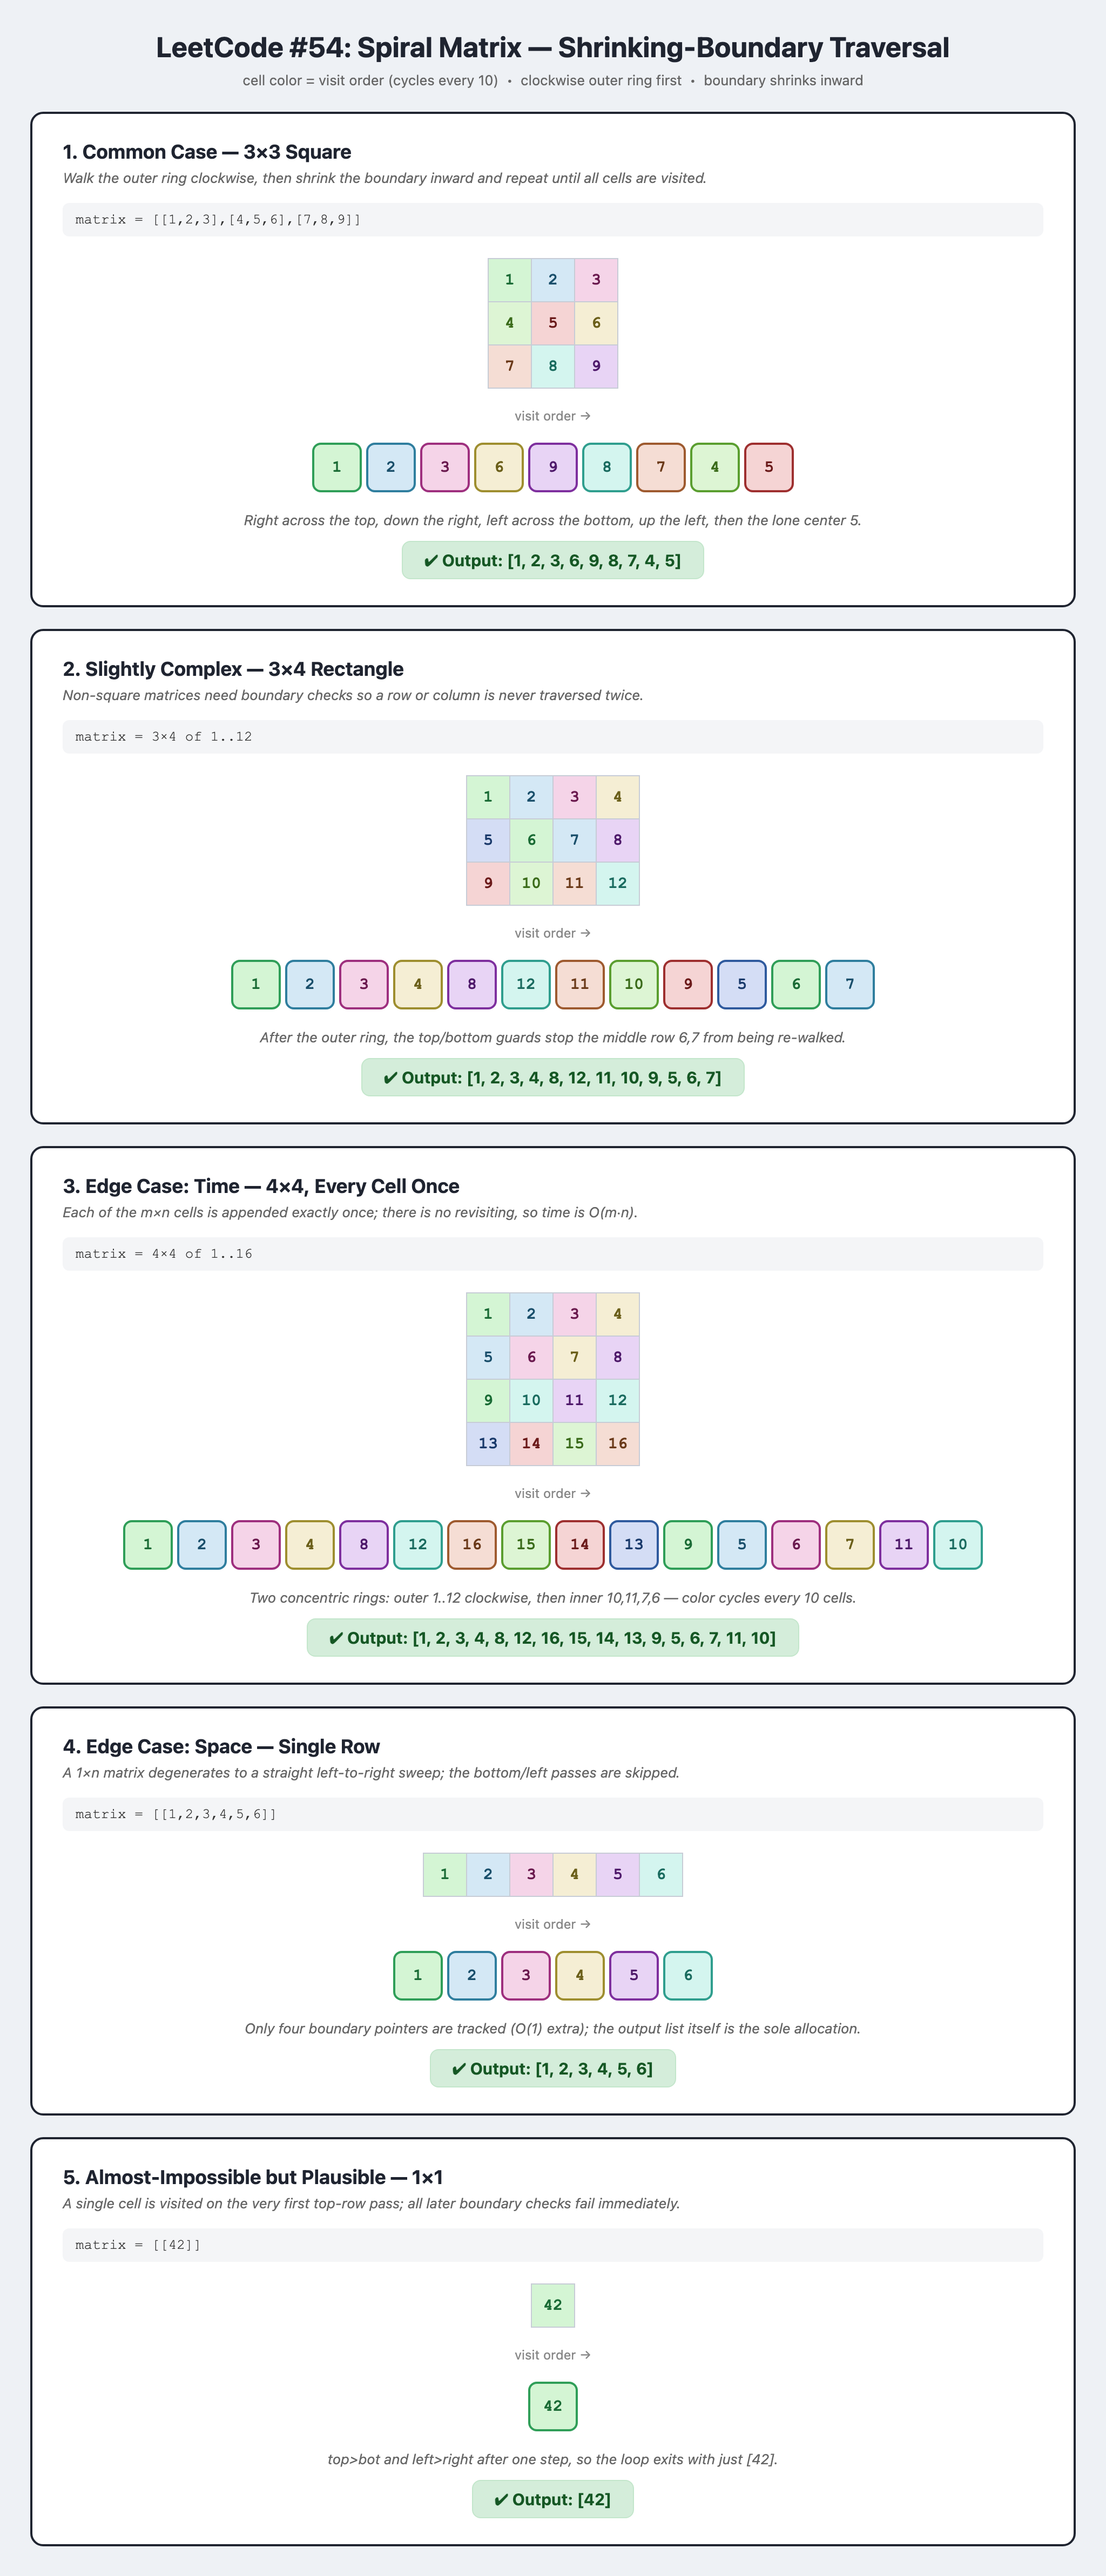